In [10]:
import sys
import os
from typing import NamedTuple
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.cross_decomposition import CCA
from sklearn.model_selection import StratifiedKFold, TimeSeriesSplit
import jax
import jax.numpy as jnp
import optax


sys.path.append(os.path.join(os.getcwd(), '../src'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../'))
from utils import plot_utils
from utils import train_utils

In [11]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [12]:
dims = 2

file_id = 0

In [13]:
# read

path = os.path.join(read_utils.get_data_path(), 'brain')
(filename,
 traces,
 states, markers) = read_utils.get_data(path, file_id)

# # clear nan values
# mask = markers.notna().all(axis=1)
#
# traces = traces[mask]
# markers = markers[mask]
# states = states[mask]

# naive ID unknown neurons

traces.columns = pd.Index([
	f'{file_id:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces.columns, traces.columns == ''))
])

In [14]:
# prep

def highpass_butter(x, fs, cutoff_hz, order=4, axis=0):
    return sp.signal.sosfiltfilt(sp.signal.butter(order, cutoff_hz, btype='highpass', fs=fs, output='sos'), x, axis=axis)

sampling_rate = read_utils.get_sampling_rate(os.path.join(path, filename))

traces = pd.DataFrame(highpass_butter(traces.values, sampling_rate, 1 / 100), columns=traces.columns)

# markers_grad = pd.DataFrame(np.gradient(marker.values, axis=0), columns=marker.columns)

In [15]:
selection_bhl = ['walk', 'still', 'front-groom', 'back-groom', 'abdomen-move', 'background']

selection_n = 5

# discrete_states = [ds[selection_bhl] for ds in discrete_states]

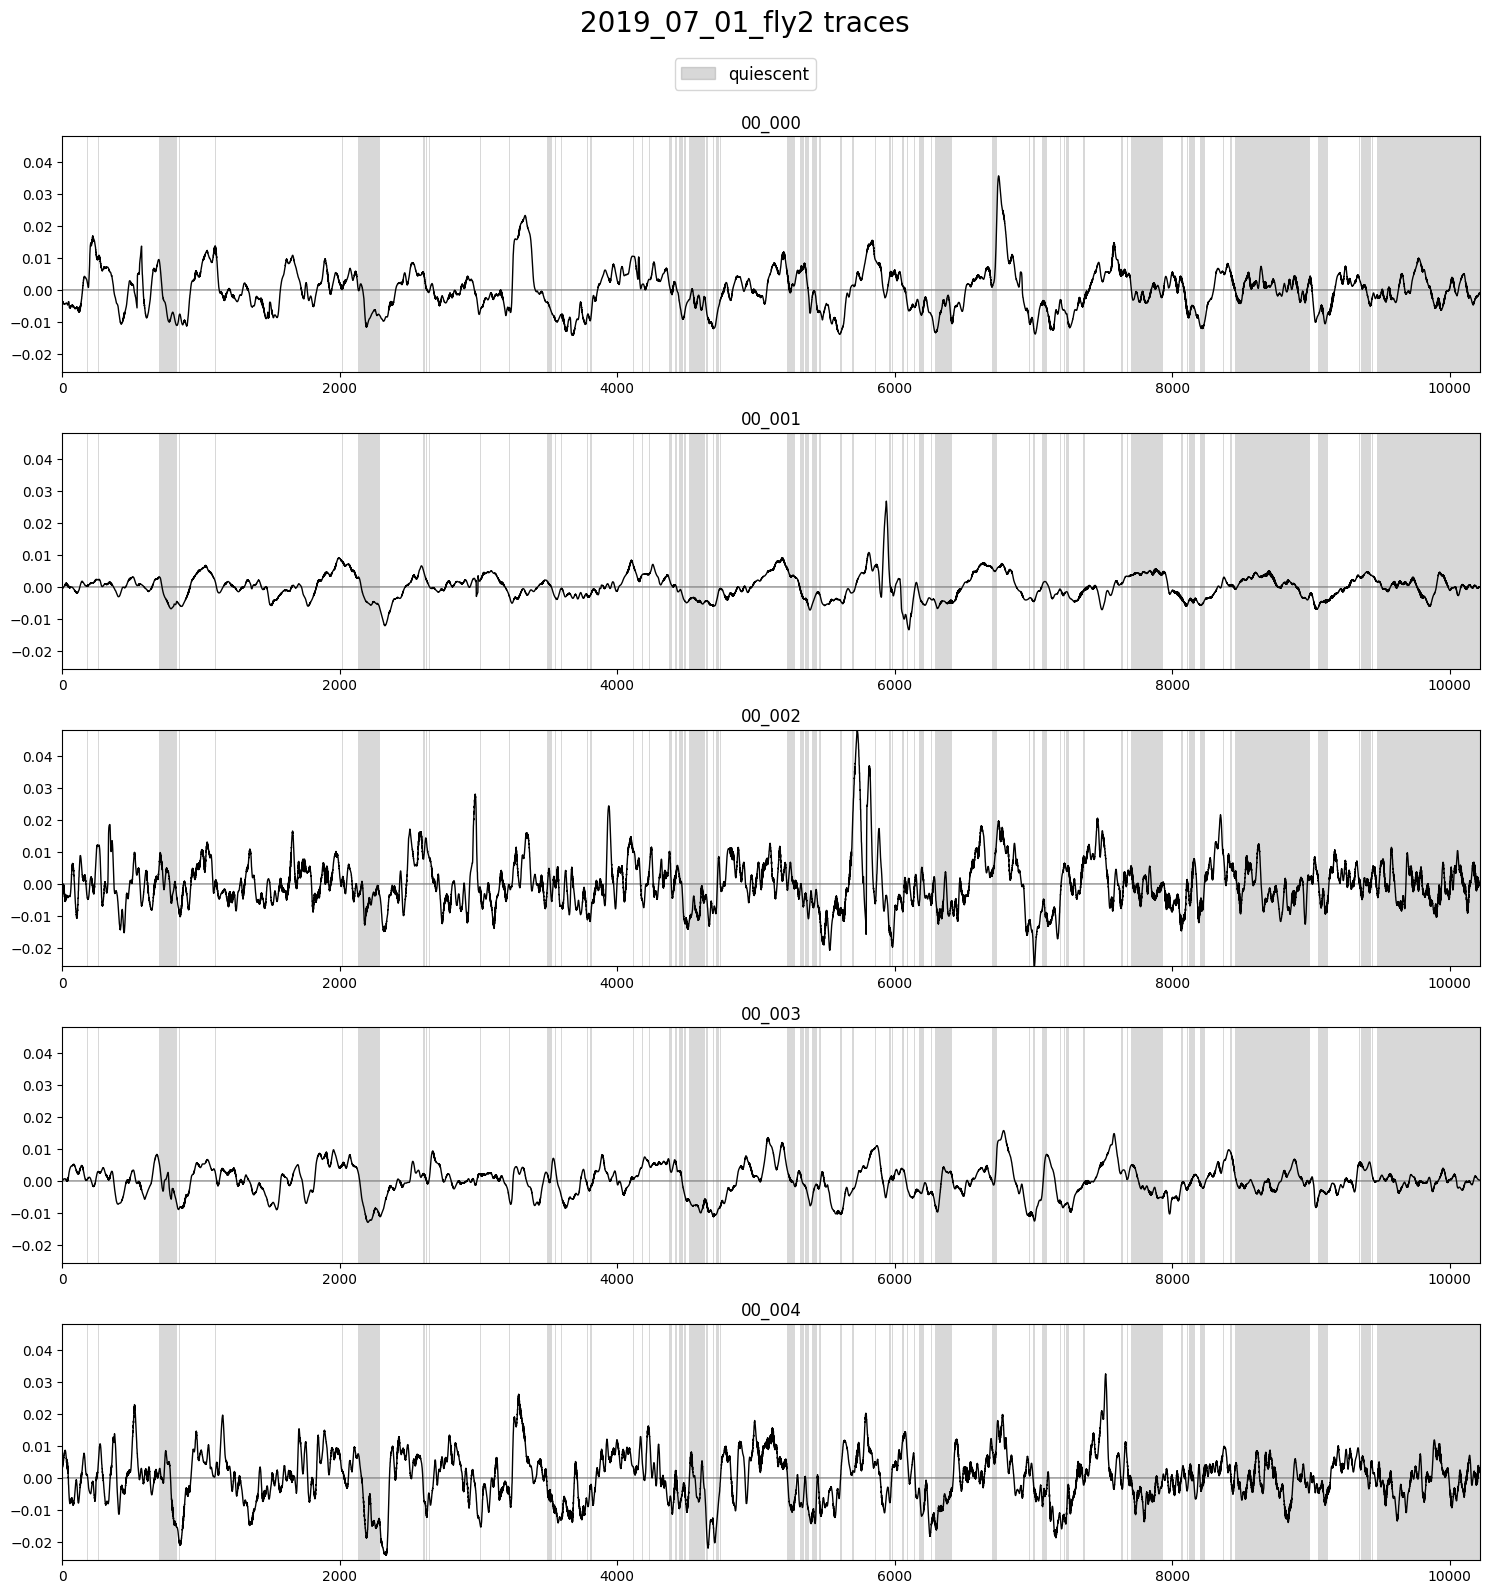

In [16]:
plot_utils.plot_traces(traces.iloc[:, :selection_n],
					   states[['still']],
					   label='quiescent',
					   title=f'{filenames} traces', ylimits=None)

# sklearn CCA

In [17]:
X = traces.values
Y = states.values

In [18]:
cca = CCA(n_components=dims, scale=True)
cca.fit(X, Y)
X_l_h, Y_l_h = cca.transform(X, Y)
X_rec_h, Y_rec_h = cca.inverse_transform(X_l_h, Y_l_h)

# def norm_temp(X_proj):
# 	X_proj = X_proj - np.mean(X_proj, axis=0)
# 	X_proj = X_proj / (np.linalg.norm(X_proj, axis=0) + 1e-6)
# 	return X_proj
# corr_a = np.array(norm_temp(X_l_h).T @ norm_temp(Y_l_h))

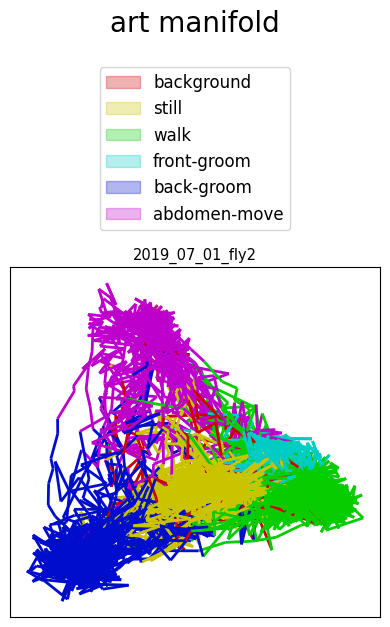

In [19]:
X_l_h_df = pd.DataFrame(data=X_l_h, columns=[f'CV{i}' for i in range(dims)])

if dims > 1:
	plot_utils.plot_manifolds([filenames],
							  [X_l_h_df],
							  [states],
							  None, None,
							  title='art manifold', top_space=2.5,
							  save_path=None)

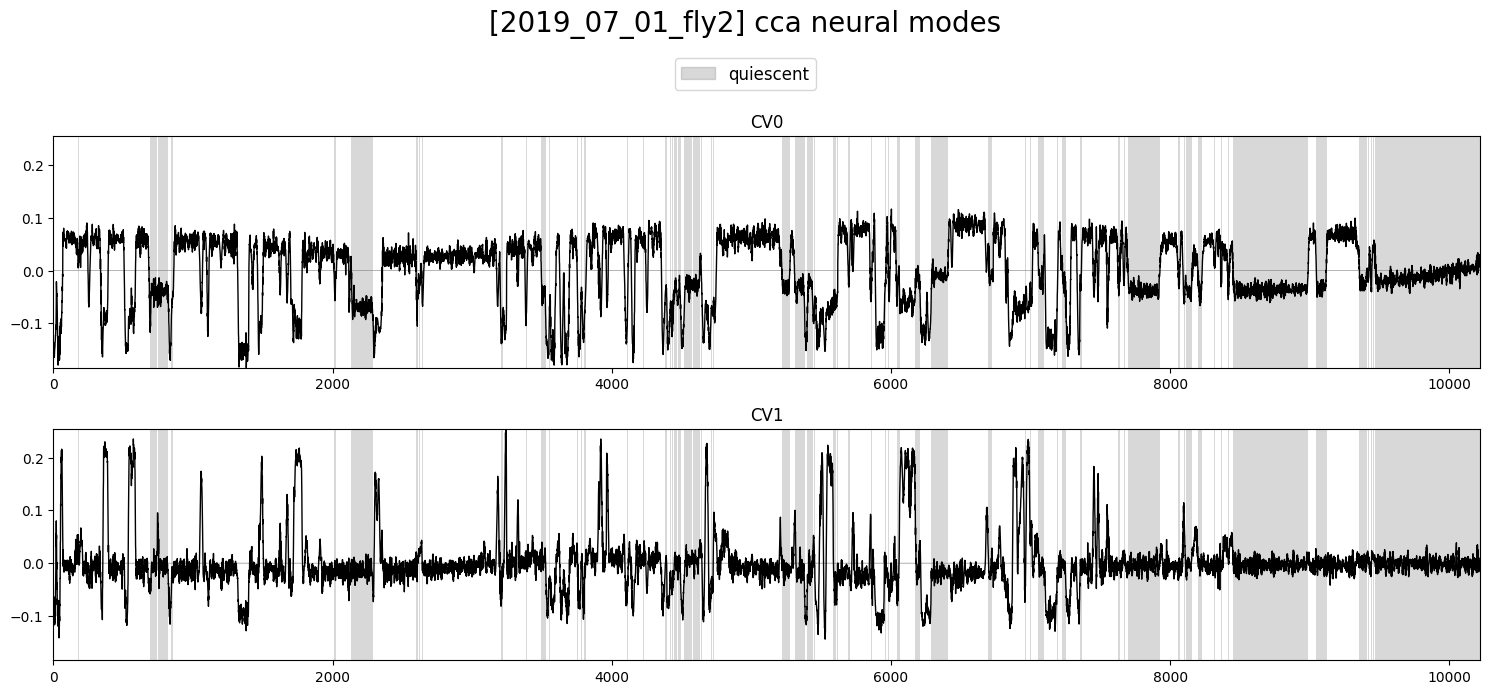

In [20]:
plot_utils.plot_traces([X_l_h_df],
					   states[['still']],
					   label='quiescent',
					   title=f'[{filenames}] cca neural modes', ylimits=None)

In [21]:
# Y_l_h_df = pd.DataFrame(data=Y_l_h, columns=[f'CV{i}' for i in range(dims)])
#
# plot_utils.plot_traces([Y_l_h_df],
# 					   states[['still']],
# 					   label='quiescent',
# 					   title=f'[{filenames}] cca behavioral modes', ylimits=None)

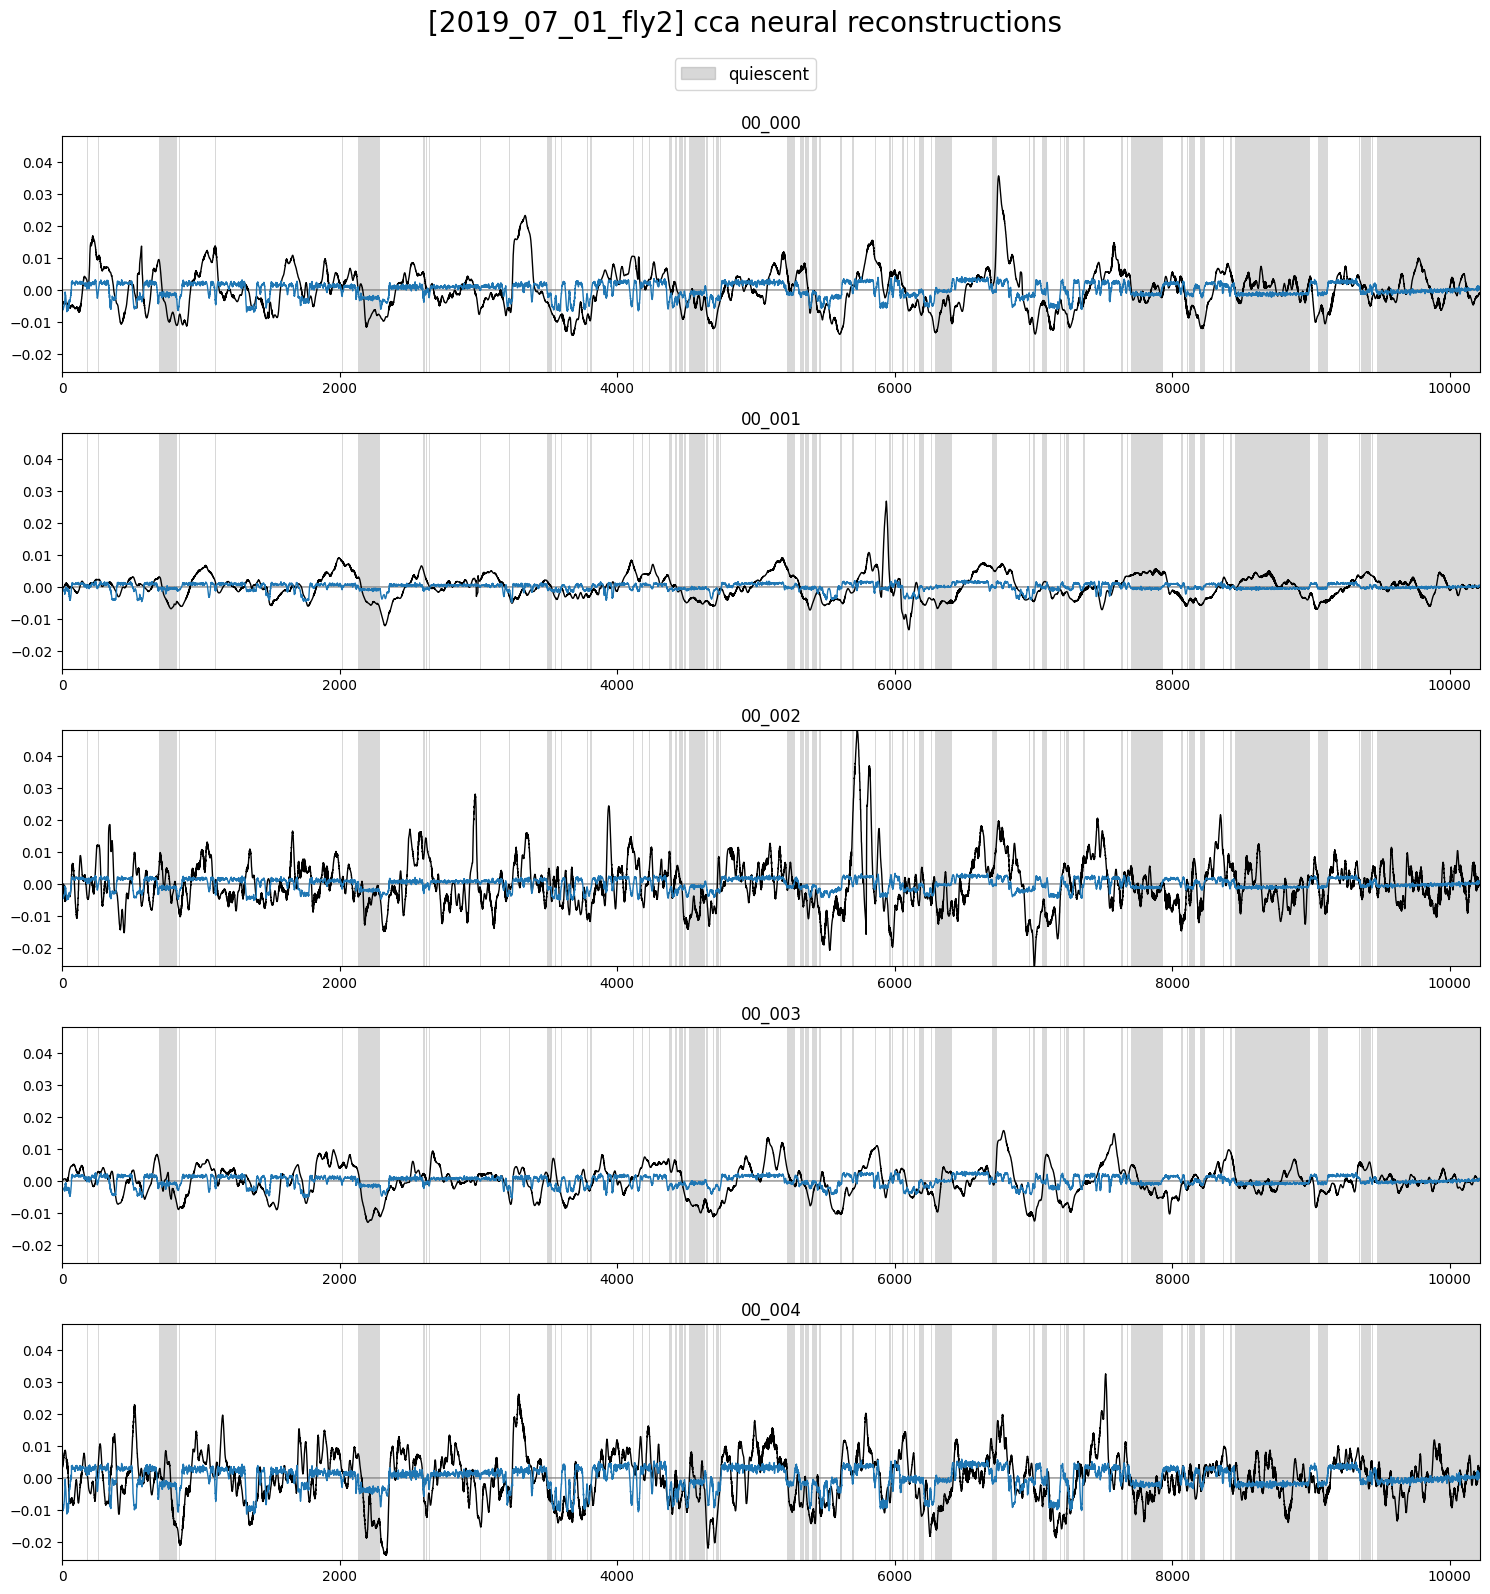

In [22]:
X_rec_h_df = pd.DataFrame(data=X_rec_h, columns=traces.columns)

plot_utils.plot_traces([traces.iloc[:, :selection_n], X_rec_h_df.iloc[:, :selection_n]],
					   states[['still']],
					   label='quiescent',
					   title=f'[{filenames}] cca neural reconstructions', ylimits=None)

In [23]:
# Y_rec_h_df = pd.DataFrame(data=Y_rec_h, columns=states.columns)
#
# plot_utils.plot_traces([states, Y_rec_h_df],
# 					   states[['still']],
# 					   label='quiescent',
# 					   title=f'[{filenames}] cca behavioral reconstructions', ylimits=None)

# soft CCA

In [24]:
class Lambdas(NamedTuple):
	cca_lambdas: tuple[float, float]


def init_params(N, S, seeds, shape_U, shape_V):
	return {
		'prep': {
			'N': {
				'mean': N.mean(axis=0),
				'std': jnp.where((N_std := jnp.std(N, axis=0)) == 0.0, 1.0, N_std),
			},
			'S': {
				'mean': S.mean(axis=0),
				'std': jnp.where((S_std := jnp.std(S, axis=0)) == 0.0, 1.0, S_std),
			},
		},
		'model': {
			'U': 1E-2 * jax.random.normal(seeds[0], shape_U),
			'V': 1E-2 * jax.random.normal(seeds[1], shape_V)
		}
	}


#@jax.jit
def norm(X_proj):
	X_proj = X_proj - jnp.mean(X_proj, axis=0)
	X_proj = X_proj / (jnp.linalg.norm(X_proj, axis=0) + 1e-6)
	return X_proj

@jax.jit
def cca_loss(X_proj, Y_proj, ccadiag_lambda, ccaunit_lambda):
	corr = norm(X_proj).T @ norm(Y_proj)

	corr_diag = jnp.diag(jnp.diag(corr))
	corr_nondiag = corr - corr_diag

	return (ccadiag_lambda * jnp.mean(jnp.abs(corr_nondiag))
			+ ccaunit_lambda * jnp.mean(jnp.abs(corr_diag - jnp.eye(*corr_diag.shape))))

#@jax.jit
def loss_fn(params, N, S, lambdas):
	ccadiag_lambda, ccaunit_lambda = lambdas.cca_lambdas

	# manifold ======================================
	prep_n = jax.lax.stop_gradient(params['prep']['N'])
	prep_s = jax.lax.stop_gradient(params['prep']['S'])

	N_mean, N_std = prep_n['mean'], prep_n['std']
	S_mean, S_std = prep_s['mean'], prep_s['std']

	U = params['model']['U']
	V = params['model']['V']

	N_zs = (N - N_mean) / N_std
	S_zs = (S - S_mean) / S_std

	N_man = N_zs @ U
	S_man = S_zs @ V

	man_loss = cca_loss(N_man, S_man, ccadiag_lambda, ccaunit_lambda)
	# ===============================================

	return man_loss

loss_and_grads = jax.jit(jax.value_and_grad(loss_fn, has_aux=False), static_argnums=(3,))


def update(opt_update, opt_state, params, N, S, lambdas):
	loss, grads = loss_and_grads(params, N, S, lambdas)
	params_updates, opt_state = opt_update(grads, opt_state, params)
	params_new = optax.apply_updates(params, params_updates)
	return opt_state, params_new, loss

In [25]:
def soft_cca_train(N, S, hyperparams):
	max_epochs = hyperparams['max_epochs']
	n_dimensions = hyperparams['dimensions']
	learning_rate = hyperparams['learning_rate']
	lambdas = Lambdas(cca_lambdas=(hyperparams['ccadiag_lambda'], hyperparams['ccaunit_lambda']))

	n_neurons = N.shape[1]
	n_behaviors_hl = S.shape[1]

	seeds = jax.random.PRNGKey(0), jax.random.PRNGKey(1)

	params = init_params(N, S, seeds, (n_neurons, n_dimensions), (n_behaviors_hl, n_dimensions))
	optimizer = optax.adam(learning_rate)
	optimizer = optax.masked(optimizer, {'prep': False, 'model': True})
	opt_state = optimizer.init(params)

	losses_train = []
	for epoch in range(max_epochs):
		opt_state, params, loss_train = update(optimizer.update, opt_state, params, N, S, lambdas)
		losses_train.append(loss_train)

	return params, losses_train


def soft_cca_predict(params, N, S):

	def get_reconstruction_matrix(Y, X):
		# best reconstruction matrix that reconstruct X using Y
		# magic (actually just analytical least-squares solution to reconstruction)
		# return jnp.linalg.inv(Y.T @ Y) @ Y.T @ X

		# return jnp.linalg.solve(Y.T @ Y + 1E-3 * jnp.eye(Y.shape[1]), Y.T @ X)
		return jnp.linalg.lstsq(Y, X, rcond=None)[0]


	prep_n = jax.lax.stop_gradient(params['prep']['N'])
	prep_s = jax.lax.stop_gradient(params['prep']['S'])

	N_mean, N_std = prep_n['mean'], prep_n['std']
	S_mean, S_std = prep_s['mean'], prep_s['std']

	U = params['model']['U']
	V = params['model']['V']

	N_zs = (N - N_mean) / N_std
	S_zs = (S - S_mean) / S_std

	N_man = N_zs @ U
	S_man = S_zs @ V

	N_zs_rec = N_man @ get_reconstruction_matrix(N_man, N_zs)
	S_zs_rec = S_man @ get_reconstruction_matrix(S_man, S_zs)

	N_rec = N_zs_rec * N_std + N_mean
	S_rec = S_zs_rec * S_std + S_mean

	return np.array(N_man), np.array(S_man), np.array(N_rec), np.array(S_rec)

In [26]:
hyperparameters = {
	'max_epochs': 5000,
	'learning_rate': 1E-1,
	'ccadiag_lambda': 0.6,
	'ccaunit_lambda': 1.0 - 0.6,
	'dimensions': dims
}
params, losses_train = soft_cca_train(X, Y, hyperparameters)
X_l_s, Y_l_s, X_rec_s, Y_rec_s = soft_cca_predict(params, X, Y)

# corr_n = np.array(norming(X_l_s).T @ norming(Y_l_s) / norming(X_l_s).shape[0])

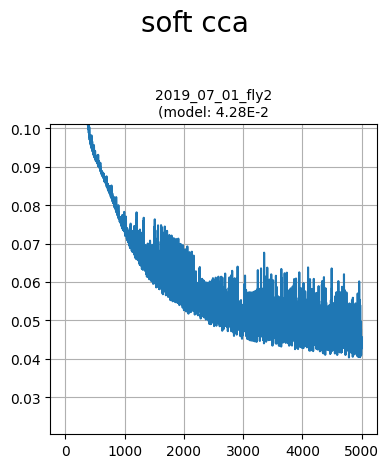

In [27]:
losses = np.array(losses_train)

plot_utils.plot_loss(filenames,
					 losses,
					 title='soft cca', ylimits=0.2, plots_per_row=1)

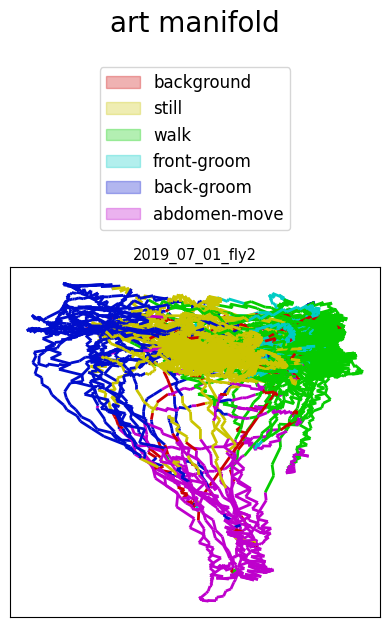

In [28]:
X_l_s_df = pd.DataFrame(data=X_l_s, columns=[f'CV{i}' for i in range(dims)])

if dims > 1:
	plot_utils.plot_manifolds([filenames],
							  [X_l_s_df],
							  [states],
							  None, None,
							  title='art manifold', top_space=2.5,
							  save_path=None)

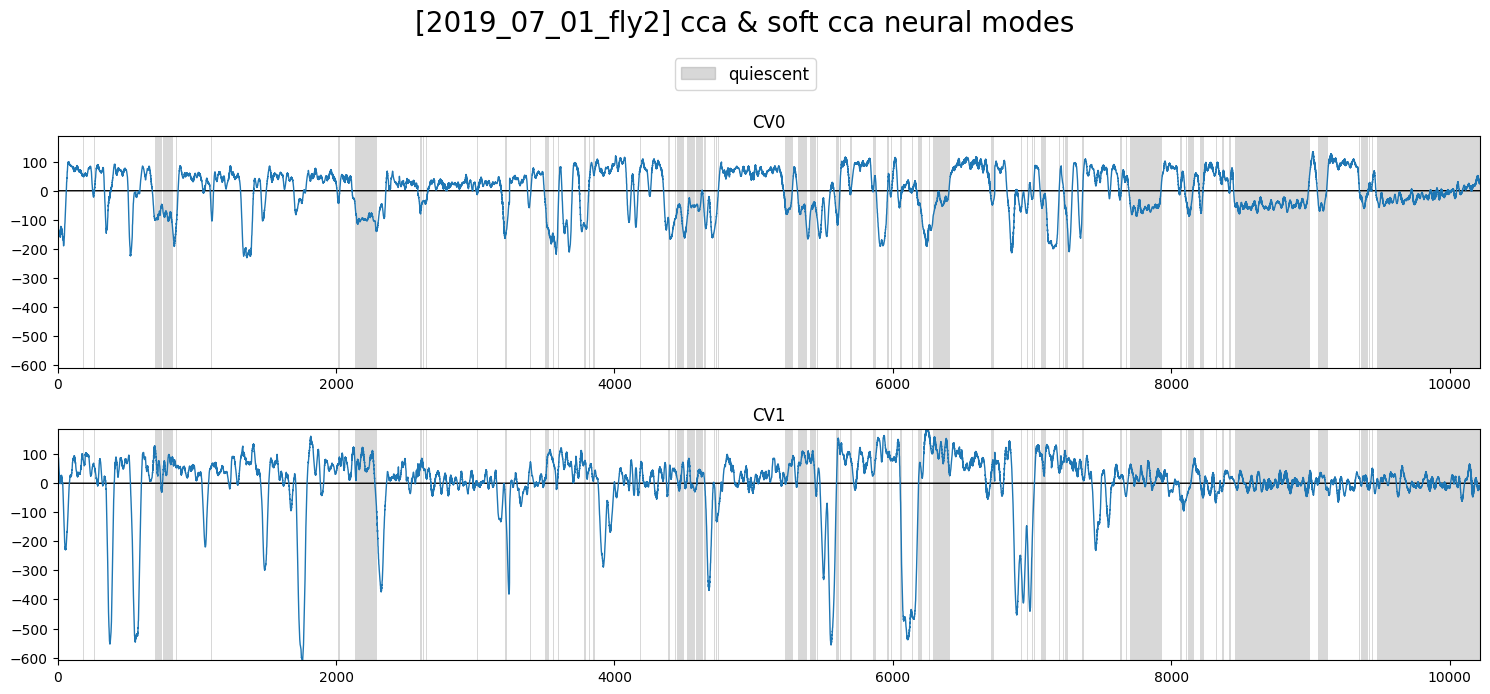

In [29]:
plot_utils.plot_traces([X_l_h_df, X_l_s_df],
					   states[['still']],
					   label='quiescent',
					   title=f'[{filenames}] cca & soft cca neural modes', ylimits=None)

In [30]:
# Y_l_s_df = pd.DataFrame(data=Y_l_s, columns=[f'CV{i}' for i in range(dims)])
#
# plot_utils.plot_traces([Y_l_h_df, Y_l_s_df],
# 					   states[['still']],
# 					   label='quiescent',
# 					   title=f'[{filenames}] cca & soft cca behavioral modes', ylimits=None)

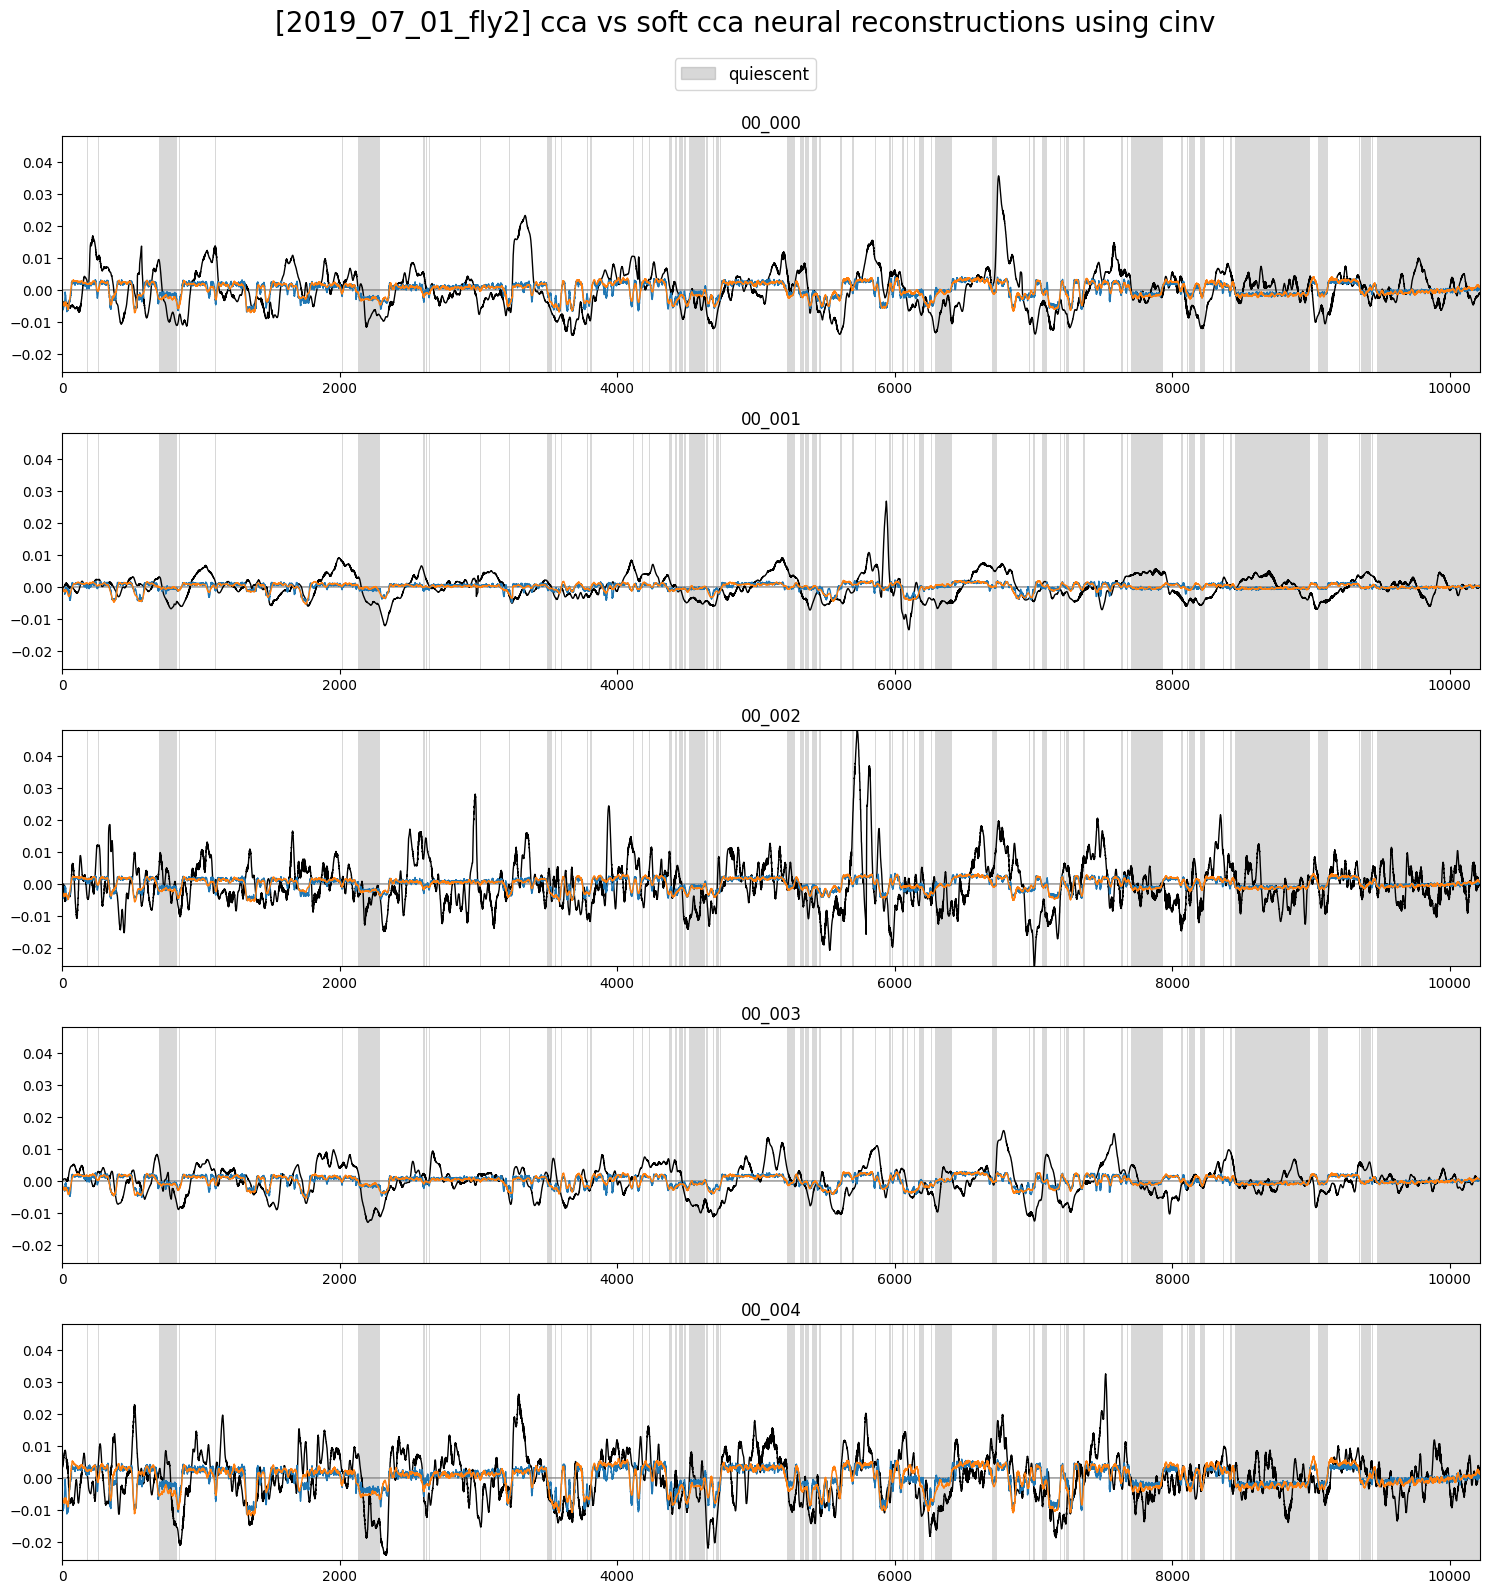

In [31]:
X_rec_s_df = pd.DataFrame(data=X_rec_s, columns=traces.columns)

plot_utils.plot_traces([traces.iloc[:, :selection_n], X_rec_h_df.iloc[:, :selection_n], X_rec_s_df.iloc[:, :selection_n]],
					   states[['still']],
					   label='quiescent',
					   title=f'[{filenames}] cca vs soft cca neural reconstructions using cinv', ylimits=None)

In [32]:
# Y_rec_s_cinv_df = pd.DataFrame(data=Y_rec_s, columns=states.columns)
#
# plot_utils.plot_traces([states, Y_rec_h_df, Y_rec_s_cinv_df],
# 					   states[['still']],
# 					   label='quiescent',
# 					   title=f'[{filenames}] cca vs soft cca behavioral reconstructions using cinv', ylimits=None)

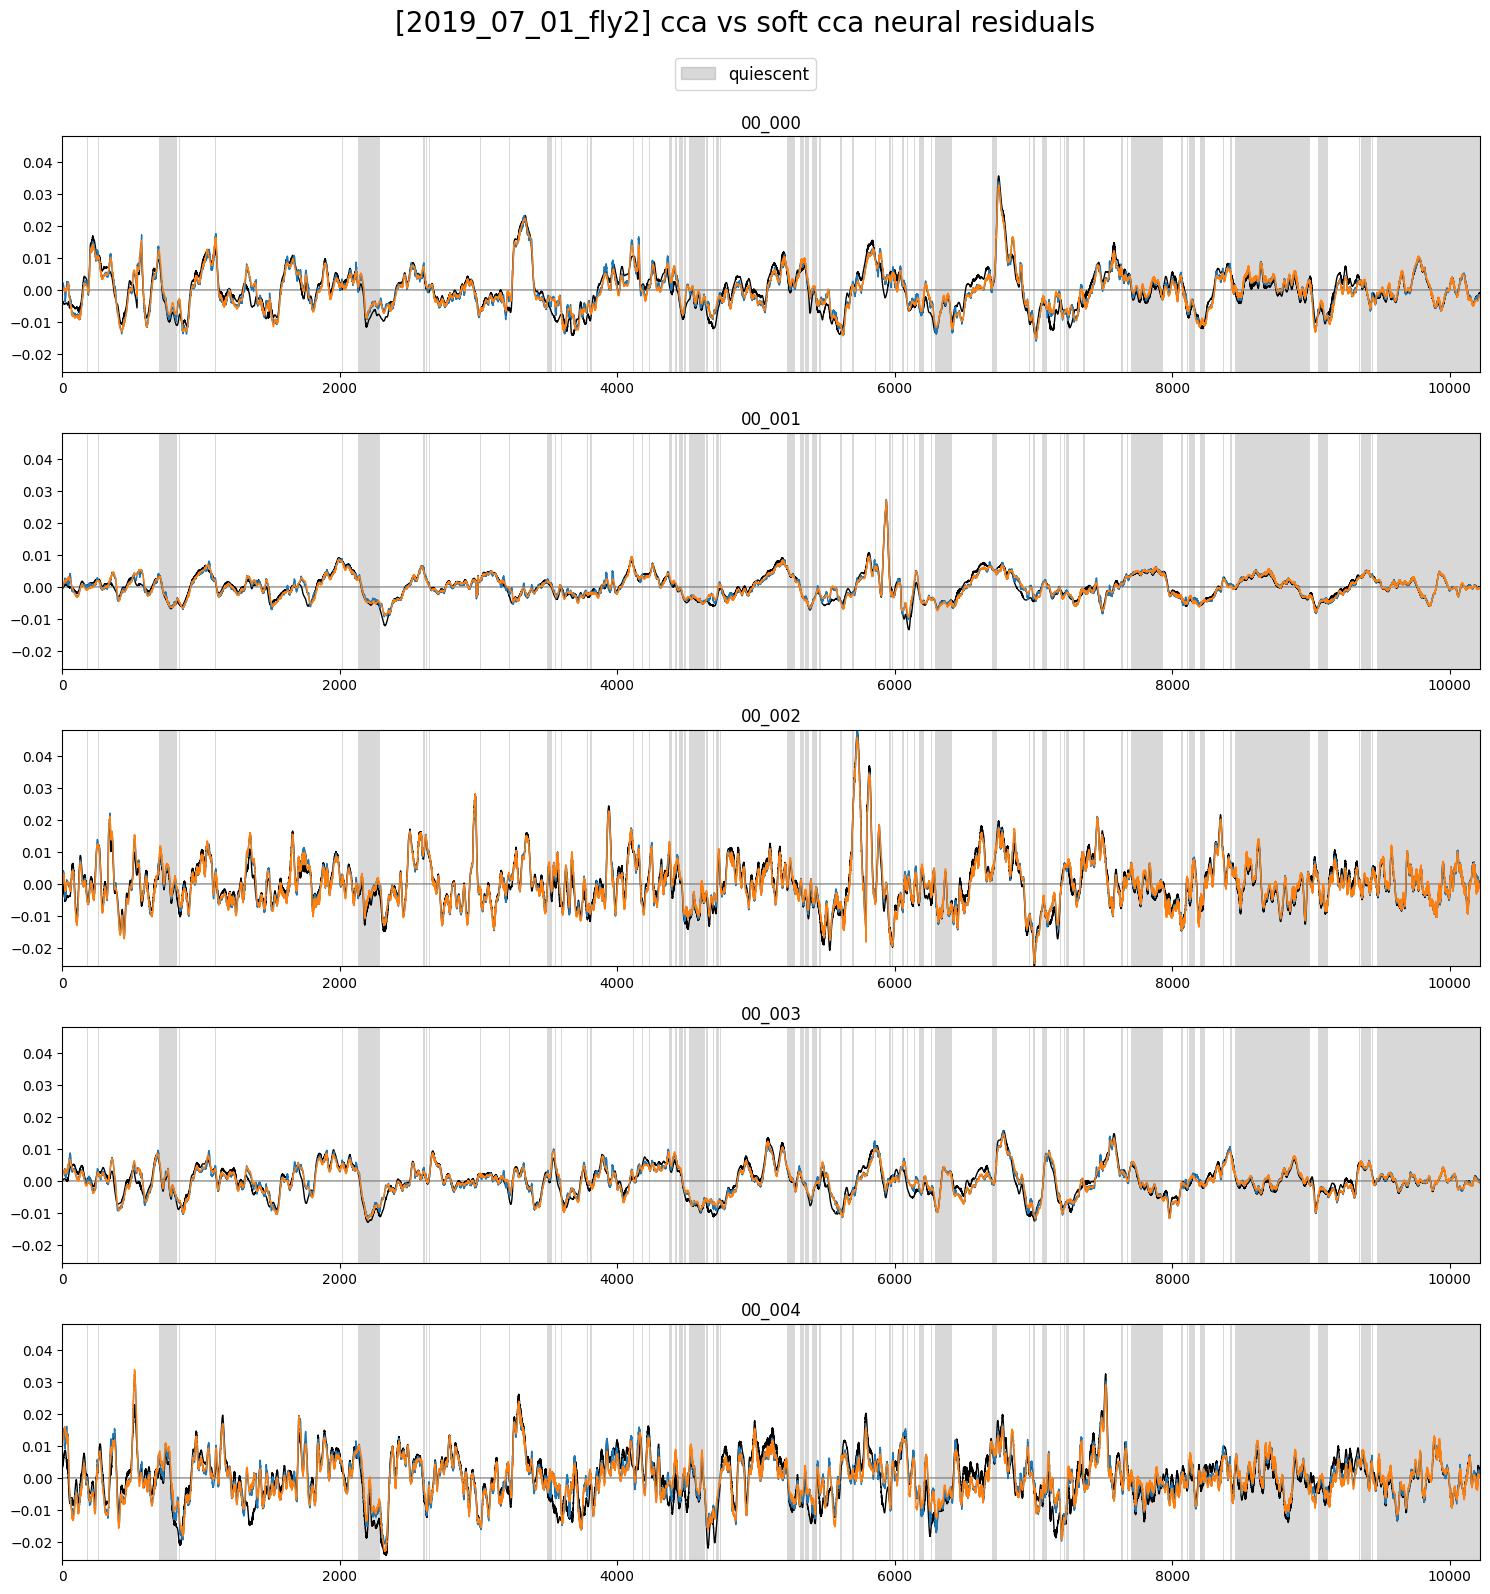

In [33]:
X_res_h_df = pd.DataFrame(data=X - X_rec_h, columns=traces.columns)
X_res_s_df = pd.DataFrame(data=X - X_rec_s, columns=traces.columns)

plot_utils.plot_traces([traces.iloc[:, :selection_n], X_res_h_df.iloc[:, :selection_n], X_res_s_df.iloc[:, :selection_n]],
					   states[['still']],
					   label='quiescent',
					   title=f'[{filenames}] cca vs soft cca neural residuals', ylimits=None)

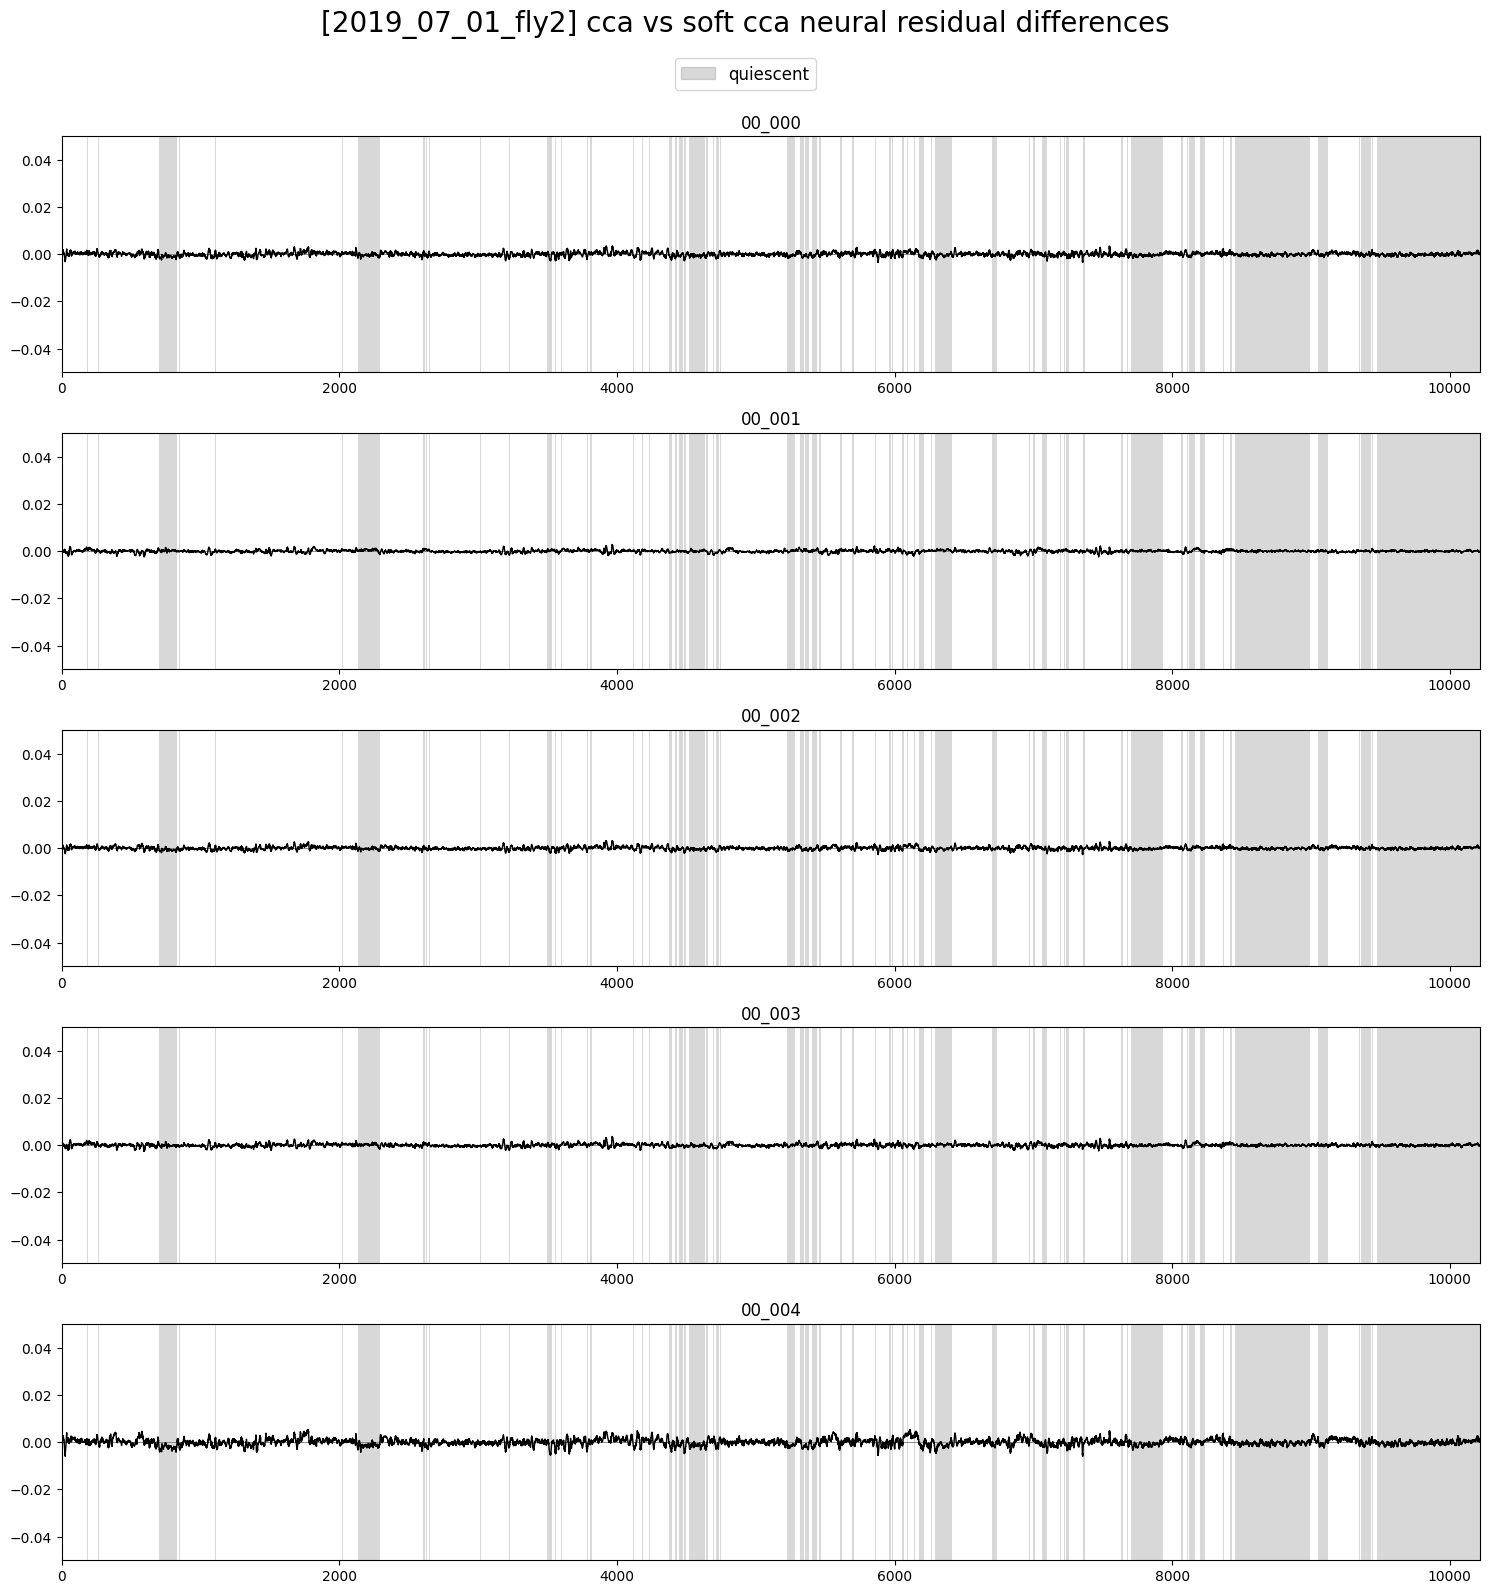

In [35]:
plot_utils.plot_traces([X_res_h_df.iloc[:, :selection_n] - X_res_s_df.iloc[:, :selection_n]],
					   states[['still']],
					   label='quiescent',
					   title=f'[{filenames}] cca vs soft cca neural residual differences', ylimits=(-0.05, 0.05))